# 04 · Candidate-based uncertainty and calibration
**Scope:** 108 H96 cells, six checkpoints, six main datasets, three seeds; 13 methods,
nominal 80/90/95% intervals. Point aggregators were refit with separate purged UQ blocks.
These forecasts are not reused from the primary fixed Learned-weights study.

We report empirical marginal coverage, width and weighted interval score (WIS). Candidate
spread is not a calibrated predictive distribution. Rolling/ACI rules additionally observe
revealed past targets online; compare their information access separately.


In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'artifacts/manifest.json').exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ttc4ts.results import (checked_path, load_snapshot, geometric, summarize,
    main_summary, lw_budget_summary, uncertainty_summary, MODELS, MODEL_LABELS, METHODS, METHOD_LABELS)
%matplotlib inline
plt.rcParams.update({'figure.dpi': 115, 'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
pd.set_option('display.max_rows', 60)
pd.set_option('display.float_format', lambda x: f'{x:.5f}')
print('Offline mode: numerical snapshots are verified against the released SHA-256 manifest.')


Offline mode: numerical snapshots are verified against the released SHA-256 manifest.


,method,coverage90,width90,relative_wis,cells,calibration
1,candidate_quantile_cp,0.90680,2.11578,0.97111,108,fixed
12,ttc_split,0.89835,2.12562,0.98536,108,fixed
8,frozen_split,0.89865,2.16827,1.00000,108,fixed
3,candidate_scale,0.89782,2.27554,1.01754,108,fixed
9,history_scale,0.89728,2.25367,1.02164,108,fixed
5,cqr,0.93143,2.45322,1.02933,108,fixed
4,candidate_spread,0.90041,2.53872,1.04328,108,fixed
6,frozen_gaussian,0.90489,2.92954,1.15549,108,fixed
10,raw_candidates,0.31399,0.31435,1.59636,108,fixed
11,ttc_rolling,0.89654,2.04287,0.96649,108,online updates


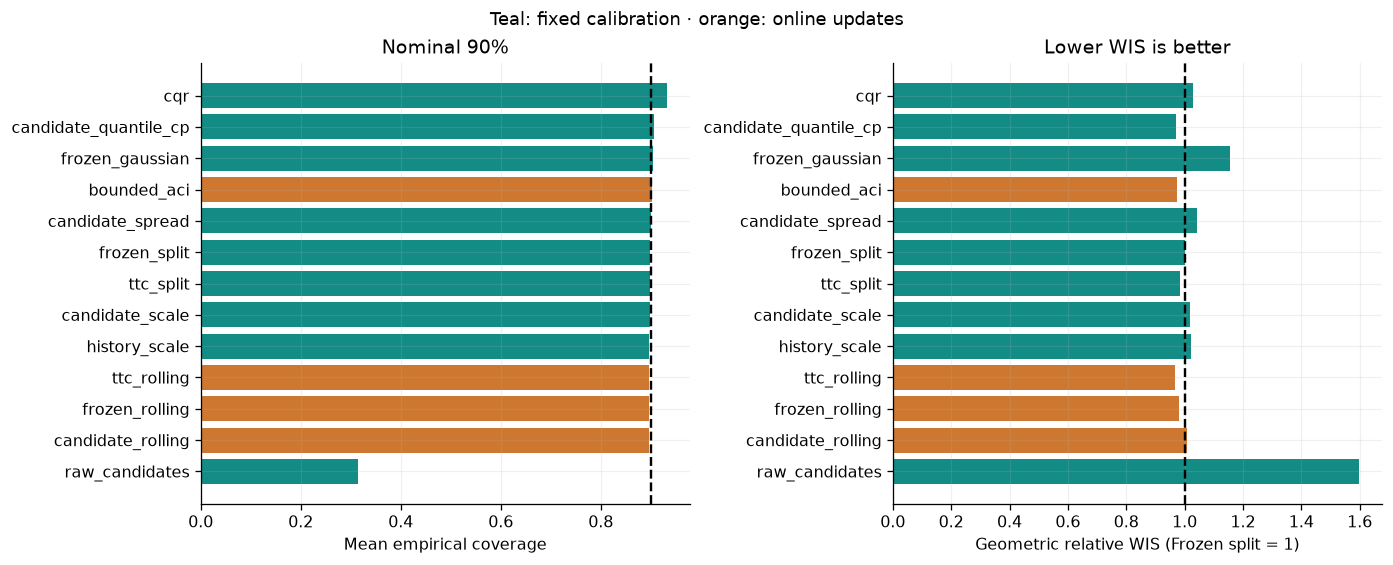

In [2]:
uq = load_snapshot('uncertainty')
assert len(uq)==108*13*3
table = uncertainty_summary()
online = {'frozen_rolling','ttc_rolling','bounded_aci','candidate_rolling'}
table['calibration'] = np.where(table.method.isin(online), 'online updates', 'fixed')
display(table.sort_values(['calibration','relative_wis']))
# WIS is repeated at each alpha in the raw CSV; count it once per cell/method.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
ordered = table.sort_values('coverage90')
color = ['#ce7731' if m in online else '#138c85' for m in ordered.method]
axes[0].barh(ordered.method, ordered.coverage90, color=color)
axes[0].axvline(.9, color='black', ls='--'); axes[0].set(xlabel='Mean empirical coverage', title='Nominal 90%')
axes[1].barh(ordered.method, ordered.relative_wis, color=color)
axes[1].axvline(1, color='black', ls='--'); axes[1].set(xlabel='Geometric relative WIS (Frozen split = 1)', title='Lower WIS is better')
fig.suptitle('Teal: fixed calibration · orange: online updates', fontsize=11); plt.show()


## Measured interval excerpt
The first saved example is Bolt-S / ETTh1 / seed 0 at the prespecified first test origin (channel OT).
Bands below are its recorded 90% intervals in fitting-standardized units. An individual window cannot establish coverage; use all 108 cells above. Intervals are
marginal, not simultaneous trajectory guarantees.


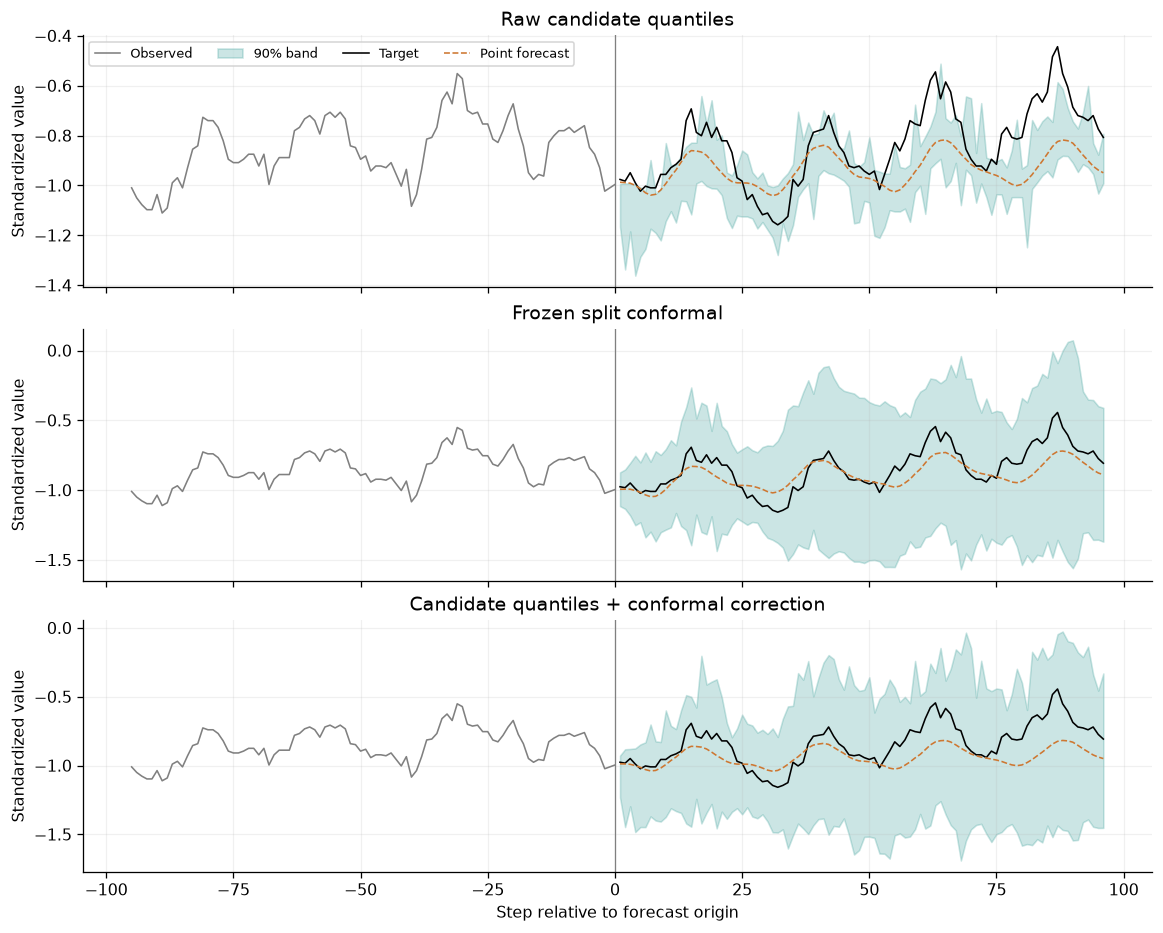

,method,example_coverage,example_mean_width
0,raw_candidates,0.47917,0.22926
1,frozen_split,1.00000,0.96586
2,candidate_quantile_cp,1.00000,0.99321


In [3]:
example = pd.read_csv(checked_path('examples/interval_1.csv'))
history = pd.read_csv(checked_path('examples/interval_1_history.csv'))
fig, axes = plt.subplots(3, 1, figsize=(10, 8), layout='constrained', sharex=True)
methods = [('raw_candidates','Raw candidate quantiles'), ('frozen_split','Frozen split conformal'),
           ('candidate_quantile_cp','Candidate quantiles + conformal correction')]
stats = []
for ax, (method, label) in zip(axes, methods):
    low, high = example[method+'_a10_lower'], example[method+'_a10_upper']
    ax.plot(history.step, history.history, color='gray', lw=1, label='Observed')
    ax.fill_between(example.step, low, high, color='#138c85', alpha=.22, label='90% band')
    ax.plot(example.step, example.target, color='black', lw=1, label='Target')
    ax.plot(example.step, example.frozen if method=='frozen_split' else example.point, '--', color='#ce7731', lw=1, label='Point forecast')
    ax.axvline(0, color='gray', lw=.8); ax.set(title=label, ylabel='Standardized value')
    stats.append(dict(method=method, example_coverage=float(((example.target>=low)&(example.target<=high)).mean()),
                      example_mean_width=float((high-low).mean())))
axes[0].legend(ncol=4, fontsize=8); axes[-1].set_xlabel('Step relative to forecast origin'); plt.show()
display(pd.DataFrame(stats))


Split conformal's finite-sample coverage statement requires exchangeability of calibration
and future scores; nonstationary time series do not automatically satisfy it. The reported
intervals are empirically evaluated, not claimed to have unconditional time-series coverage.
All six saved examples can be plotted by changing the excerpt number above. Full fitting
implementations live in `ttc4ts/uncertainty.py` and `scripts/run_uncertainty.py`.
